# Machine learning-based surrogate modeling with application to a tsunami case

## Load modules

The tutorial is based on the python module [scikit-learn](https://scikit-learn.org/): a Python module integrating a wide range of state-of-the-art machine learning algorithms for medium-scale supervised and unsupervised problems. See details [Pedregosa et al. (2011)](http://www.jmlr.org/papers/volume12/pedregosa11a/pedregosa11a.pdf?source=post_page).

In [1]:
# load specific functions for manipulating, plotting data
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# load specific functions of sklearn
from sklearn.metrics import r2_score
from sklearn.metrics import mean_absolute_error
from sklearn import model_selection
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Import all regression models you want to test
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR

## Context

The application test case is adapted from the Ligurian (North West of Italy) 1887 tsunami case in particular studied by [Larroque et al. (2012)](https://academic.oup.com/gji/article/190/1/87/601785). The following figure provides the structural scheme of the fault rupture mechanism.

![ligurianEarthquake.png](./data/ligurianEarthquake.png).

We will focus on the impact of the uncertainties of the earthquake source parameters on the the sea surface elevatio denoted *SSH* induced by the tsunami. Nine uncertain parameters are considered:
* $X_{1} = Lon$, Longitude of the  epicentral position (°)
* $X_{2} = Lat$, Latitude of the  epicentral position (°)
* $X_{3} = Z$, Depth  (m)
* $X_{4} = Azi$, Azimuth  (°)
* $X_{5} = Dip$, Dip angle  (m)
* $X_{6} = Rake$, Rake angle  (°)
* $X_{7} = D$, average slip on the fault surface  (m)
* $X_{8} = W$, Width of the fault surface  (m)
* $X_{9} = L$, Length of the fault surface  (m)

A numerical model has been set up to estimate the tsunami-induced sea surface elevation at different locations along the French and Italian coast from the values of the earthquake source parameters. See details in [Rohmer et al. 2018](https://link.springer.com/article/10.1007/s00477-017-1423-y).
The model has $8$ input random variables. A set of 300 random samples was generated by assuming that all input variables vary uniformly between the lower and upper bound described in the Table below.
![Table](./data/Assumption.png)
For each input sample, a numerical model is run to compute the response (sea surface elevation) at all points along the coast.
![location.png](./data/location.png)

## Objectives
The objective is to model the mathematical link between the input parameters *X* and *SSH* using a machine learning model. 

In this tutorial, you will:
* train a [random forest regression model](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html) and assess its prediction capability via cross validation procedure
* select the most optimal hyper-parameters of this model
* compare to alternative machine learning models
* select the most optimal model and tune its hyper-parameters

## Data

In [2]:
##Load the inputs
df = pd.read_csv("./data/DOE_aziPetit.txt",sep=" ")
X = df.values
d = df.shape[1] # number of inputs
N = df.shape[0] # number of samples

**QUESTION 1** Create cloud pairs graphs to visualise the input values and their distribution using [seaborn pairplot](https://seaborn.pydata.org/generated/seaborn.pairplot.html). What can you say about the distribution of the inputs?

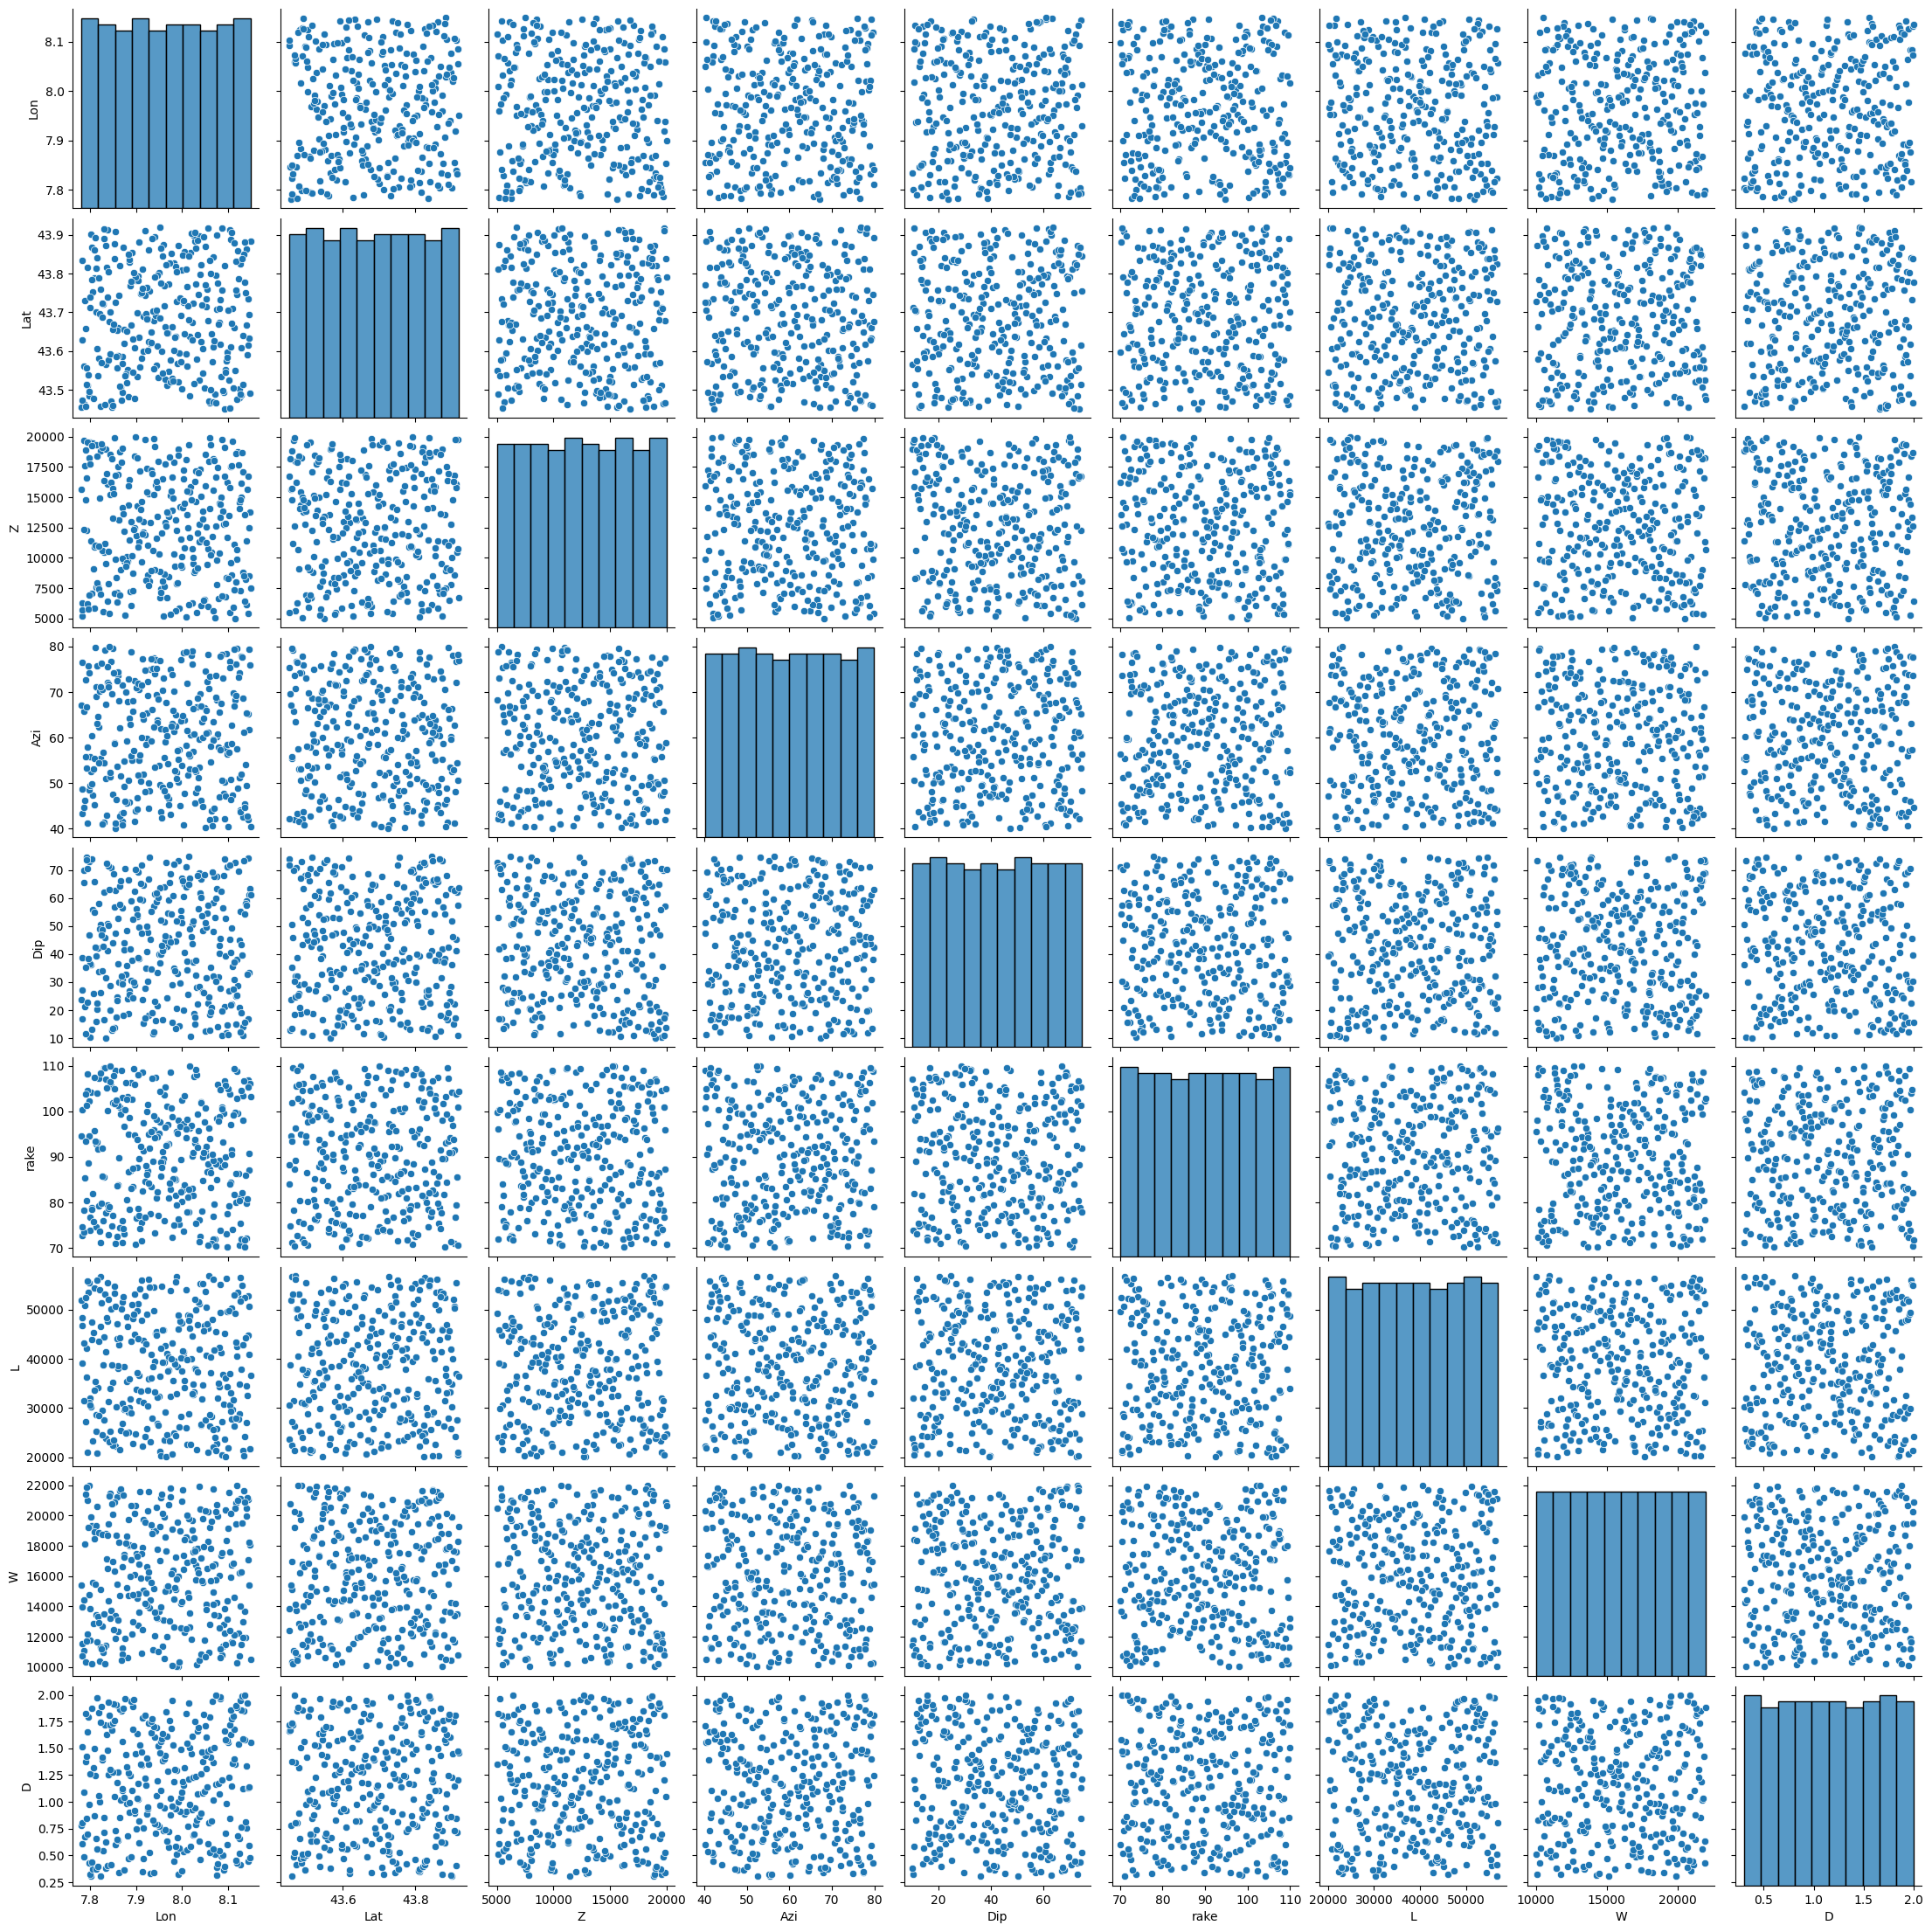

In [3]:
sns.pairplot(df)

In [4]:
##Load the response (output)
outputSample0  = pd.read_csv("./data/Hmax_aziPetit.txt",sep=" ", header=None)

We wil first focus on location #8 =  Imperia (see map above).

In [5]:
loc = 8
Y = outputSample0.values[:,loc]
TARGET_LABEL = ["SSH" + str(loc) + ' [m]']

We plot here the histogram of output *Y*.

**QUESTION 2** what can you say about the characteristics of *Y*

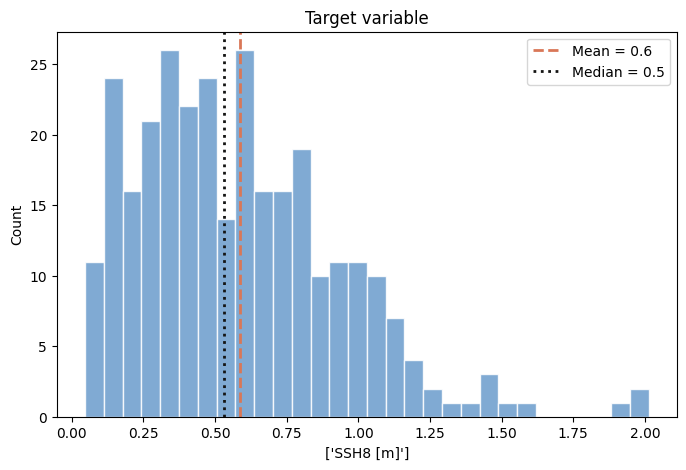

In [6]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(Y, bins=30, edgecolor="white", alpha=0.85, color="#6a9bcc")
ax.axvline(np.mean(Y), color="#d97757", linestyle="--", linewidth=2, label=f"Mean = {np.mean(Y):.1f}")
ax.axvline(np.median(Y), color="#141413", linestyle=":", linewidth=2, label=f"Median = {np.median(Y):.1f}")
ax.set_xlabel(TARGET_LABEL); ax.set_ylabel("Count")
ax.set_title("Target variable")
ax.legend()
#plt.savefig(IMAGES_DIR / "ml_target_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

## Surrogate modelling with a machine learning model

We will first split the dataset (X,Y) in training and test subsets by following a 5-fold cross-validation procedure repeated 5 times. See details [here](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RepeatedKFold.html).
To assess the predictive performance, we choose as a scoring criterion the [r²](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.r2_score.html).

In [7]:
## define the cross validation procedure
kfold = model_selection.RepeatedKFold(n_splits=2,n_repeats=1, random_state=42)
scoring = 'r2'

We will fit and test the performance of a [random forest regression model](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html).

In [8]:
## fit the rf model
rf0 = RandomForestRegressor(random_state=0)
rf0.fit(X,Y)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [9]:
## perform the CV procedure
cv_results = model_selection.cross_val_score(rf0, X, Y, cv=kfold, scoring=scoring)
msg = "%f (%f)" % (cv_results.mean(), cv_results.std())
print(msg)

0.586088 (0.022049)


## Play with the hyper-parameters

Different hyer-parameters can be defined. See the list [here](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html). Hereafeter, we will change some of them, and we will test which model has the highest performance score.

In [10]:
# Initialize models
models = []
models.append(('RF0', RandomForestRegressor()))
models.append(('RF1', RandomForestRegressor(max_features = 3,  n_estimators = 1000)))
models.append(('RF2', RandomForestRegressor(max_features = 3,  n_estimators = 100)))
models.append(('RF3', RandomForestRegressor(max_features = 6,  n_estimators = 1000)))
models.append(('RF4', RandomForestRegressor(max_features = 1,  n_estimators = 100)))
models.append(('RF5', RandomForestRegressor(max_features = 1,  n_estimators = 1000)))

In [11]:
# CV
results = []
names = []
for name, model in models:
    cv_results = model_selection.cross_val_score(model, X, Y, cv=kfold, scoring=scoring)
    results.append(cv_results)
    names.append(name)
    msg = "%s: %f (%f)" % (name, cv_results.mean(), cv_results.std())
    print(msg)

RF0: 0.593552 (0.005122)
RF1: 0.592666 (0.010617)
RF2: 0.574030 (0.008532)
RF3: 0.594712 (0.005229)
RF4: 0.479559 (0.037709)
RF5: 0.492518 (0.044023)


**QUESTION 3** Plot the histogram of the score values. Which model appears to perform the best? What can you say about the other models? Which hyper-parameter has the largest influence?

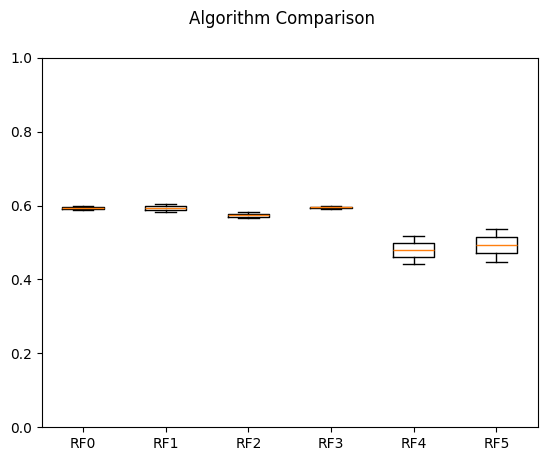

In [12]:
# boxplot algorithm comparison
fig = plt.figure()
fig.suptitle('Algorithm Comparison')
ax = fig.add_subplot(111)
plt.boxplot(results)
ax.set_xticklabels(names)
plt.ylim(0, 1)
plt.show()

listofmeans = [np.mean(i) for i in results]
id = np.argmax(listofmeans)

## More systematic tuning

We use the function [gridsearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html) to tune automaticcally the hyper-parameters.

**QUESTION 4** Choose a list of possible values (replace ## TBC ## by values) of the hyper-parameters and run the code to search for the most optimal configuration.

In [14]:
# Number of trees in random forest
n_estimators = [1000]#, 500, 1000, 2000]
#[int(x) for x in np.linspace(start = 100, stop = 1000, num = 10)]
# Number of features to consider at every split
max_features = [4,5,6]#,3,4]
# Maximum number of levels in tree
max_depth = [None]
# Minimum number of samples required to split a node
min_samples_split = [2, 5]#, 10]
# Minimum number of samples required at each leaf node
min_samples_leaf = [1, 2]#, 4]
# Method of selecting samples for training each tree
bootstrap = [True]

# Create the random grid
para_grid = {'n_estimators': n_estimators,
               'max_features': max_features,
               'max_depth': max_depth,
               'min_samples_split': min_samples_split,
               'min_samples_leaf': min_samples_leaf,
               'bootstrap': bootstrap}
print(para_grid)

#rf_random = RandomizedSearchCV(
rf_random = GridSearchCV(
    estimator = rf0, 
    cv = kfold, 
    param_grid = para_grid,
    verbose = 10,
    scoring =  scoring,
    refit = True
    )

rf_random.fit(X,Y)

{'n_estimators': [1000], 'max_features': [4, 5, 6], 'max_depth': [None], 'min_samples_split': [2, 5], 'min_samples_leaf': [1, 2], 'bootstrap': [True]}
Fitting 2 folds for each of 12 candidates, totalling 24 fits
[CV 1/2; 1/12] START bootstrap=True, max_depth=None, max_features=4, min_samples_leaf=1, min_samples_split=2, n_estimators=1000
[CV 1/2; 1/12] END bootstrap=True, max_depth=None, max_features=4, min_samples_leaf=1, min_samples_split=2, n_estimators=1000;, score=0.596 total time=   3.7s
[CV 2/2; 1/12] START bootstrap=True, max_depth=None, max_features=4, min_samples_leaf=1, min_samples_split=2, n_estimators=1000
[CV 2/2; 1/12] END bootstrap=True, max_depth=None, max_features=4, min_samples_leaf=1, min_samples_split=2, n_estimators=1000;, score=0.602 total time=   3.7s
[CV 1/2; 2/12] START bootstrap=True, max_depth=None, max_features=4, min_samples_leaf=1, min_samples_split=5, n_estimators=1000
[CV 1/2; 2/12] END bootstrap=True, max_depth=None, max_features=4, min_samples_leaf=1,

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestR...andom_state=0)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'bootstrap': [True], 'max_depth': [None], 'max_features': [4, 5, ...], 'min_samples_leaf': [1, 2], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",RepeatedKFold...ndom_state=42)
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold a

**CHALLENGE** Which configuration achieves the best score?

In [15]:
print(rf_random.best_params_)
print(rf_random.best_score_)
best_model = rf_random.best_estimator_
best_model

{'bootstrap': True, 'max_depth': None, 'max_features': 5, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 1000}
0.6085656030909019


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",1000
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",5
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples

## Test alternative models

Now we will test other machine learning models, i.e., [linear regression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html), [support vector machine](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVR.html) for regression, and [gradient boosting](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.GradientBoostingRegressor.html).

In [16]:
models = {
    "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
    "Support Vector Regressor (SVR)": make_pipeline(StandardScaler(), SVR(kernel='rbf')),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=100, random_state=42)
}

In [17]:
# CV
results = []
names = []
for name, model in models.items():
    cv_results = model_selection.cross_val_score(model, X, Y, cv=kfold, scoring=scoring)
    results.append(cv_results)
    names.append(name)
    msg = "%s: %f (%f)" % (name, cv_results.mean(), cv_results.std())
    print(msg)

Linear Regression: 0.672195 (0.014087)
Support Vector Regressor (SVR): 0.707305 (0.066933)
Random Forest: 0.603779 (0.005420)
Gradient Boosting: 0.683503 (0.007842)


**QUESTION 5** Which model has the best score? Could you comment also on the value of the standard deviation?

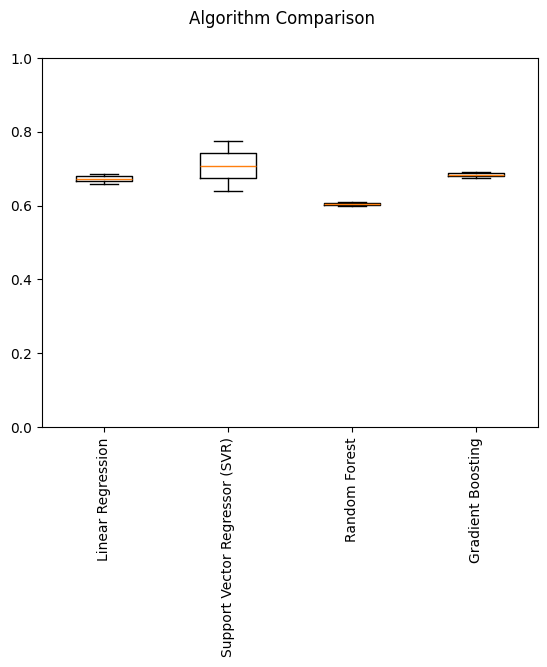

In [18]:
# boxplot algorithm comparison
fig = plt.figure()
fig.suptitle('Algorithm Comparison')
ax = fig.add_subplot(111)
plt.boxplot(results)
plt.xticks(rotation='vertical')
ax.set_xticklabels(names)
plt.ylim(0, 1)
plt.show()

listofmeans = [np.mean(i) for i in results]
id = np.argmax(listofmeans)

## Tune the most optimal model

**QUESTION 6** Select the best performing model and tune its hyper-parameter. 
*Hints* to tune hyperparameters of a pipeline please adapte the above code by following [example](https://stackoverflow.com/questions/43366561/use-sklearns-gridsearchcv-with-a-pipeline-preprocessing-just-once).

In [20]:
sv0 = make_pipeline(StandardScaler(), SVR(kernel='rbf')).fit(X,Y)
C_list = [0.01,0.02,0.03,0.05,0.1,0.2,0.3,0.5,1,2,3,5,10,20,30,100]
gamma_list = [0.01,0.02,0.03,0.05,0.1,0.2,0.3,0.5,1,2,3,5,10]

# Create the random grid
para_grid = {  'svr__gamma': gamma_list,
               'svr__C': C_list}
print(para_grid)

#rf_random = RandomizedSearchCV(
svm_random = GridSearchCV(
    estimator = sv0, 
    cv = kfold, 
    param_grid = para_grid,
    verbose = 1,
    scoring =  scoring,
    refit = True
    )

svm_random.fit(X,Y)

{'svr__gamma': [0.01, 0.02, 0.03, 0.05, 0.1, 0.2, 0.3, 0.5, 1, 2, 3, 5, 10], 'svr__C': [0.01, 0.02, 0.03, 0.05, 0.1, 0.2, 0.3, 0.5, 1, 2, 3, 5, 10, 20, 30, 100]}
Fitting 2 folds for each of 208 candidates, totalling 416 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...svr', SVR())])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'svr__C': [0.01, 0.02, ...], 'svr__gamma': [0.01, 0.02, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",RepeatedKFold...ndom_state=42)
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2

In [21]:
print(svm_random.best_params_)
print(svm_random.best_score_)
best_model = svm_random.best_estimator_
best_model

{'svr__C': 30, 'svr__gamma': 0.01}
0.8201415030446821


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('standardscaler', ...), ('svr', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm.If none is given, 'rbf' will be used. If a callable is given it isused to precompute the kernel matrix.For an intuitive visualization of different kernel typessee :ref:`sphx_glr_auto_examples_svm_plot_svm_regression.py`",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",0.01
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0


**QUESTION 7** Test the same model but without the pre-scaling. To do so, set *svr0* to *SVR(kernel='rbf')*.

## Advanced mode

**QUESTION 9** Perform two new analyses:
* 1. change the number of folds from 5 to 10 and the number of repeatitions from 5 to 1
* 2. change the scoring to 'neg_mean_absolute_error'

For each analysis, note the differences in the conclusions.